# Analisi preliminare fit ibrido con NLL

Configurazioni caricate -> CNN Pura: 48 | Ibrido LS: 48 | Ibrido NLL: 48
Diagnostica Ibrido NLL -> Minuit valido medio: 89.6% | Fallback a CNN medio: 10.4%


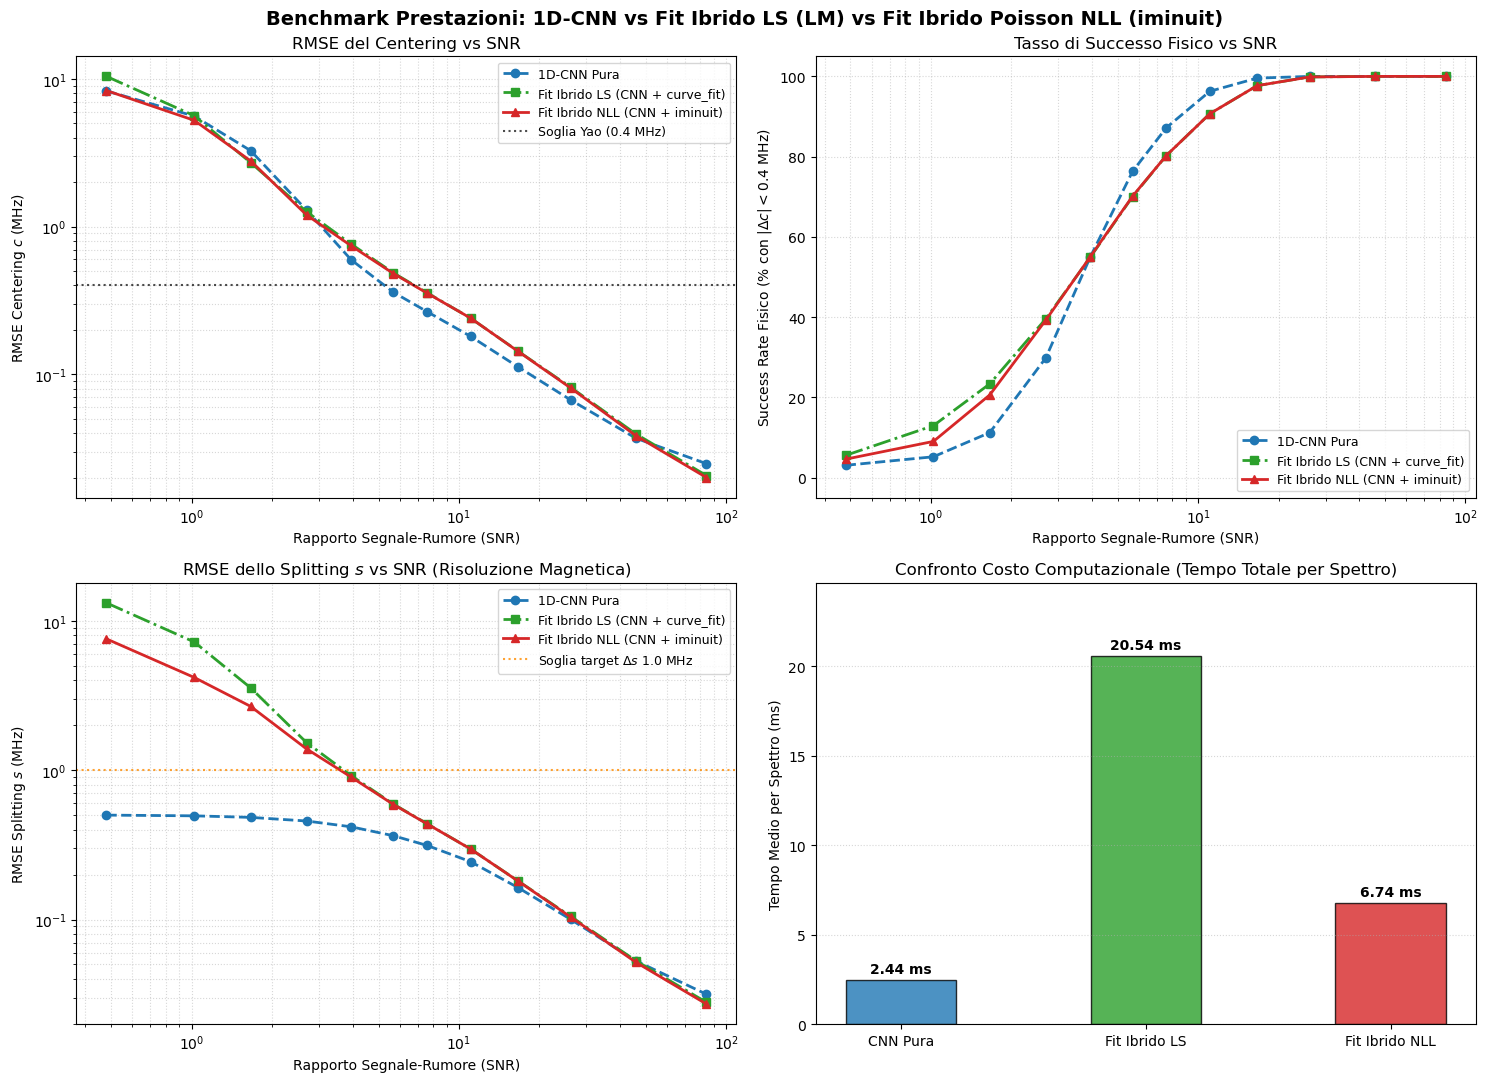

In [1]:
import glob
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =========================================================================
# 1. SCANSIONE DEI CSV: CNN PURA, IBRIDO LS (curve_fit) E IBRIDO NLL (iminuit)
# =========================================================================
dir_model_base = os.path.abspath("../benchmarks/10k/model")
dir_hybrid_ls_base = os.path.abspath("../benchmarks/10k/hybrid")
dir_hybrid_nll_base = os.path.abspath("../benchmarks/10k/hybrid_likelihood")

K_points = 335            # Griglia DOPPIA DENSITÀ (335 punti)
delta_sweep_mhz = 200.0   # Finestra fisica [2.75, 2.95] GHz
soglia_successo_mhz = 0.4 # Soglia fisica Yao et al. (~5 K)


def parse_benchmark_folder(folder_path: str, method_label: str) -> pd.DataFrame:
    files = glob.glob(os.path.join(folder_path, "**", "*.csv"), recursive=True)
    records = []

    for filepath in files:
        match_c = re.search(r"contrast=([\d\.]+)", filepath)
        match_n = re.search(r"Nph(\d+)", filepath)
        if not (match_c and match_n):
            continue

        c_val = float(match_c.group(1))
        n_ph = float(match_n.group(1))

        # Calcolo analitico SNR di singolo canale
        snr_val = c_val * np.sqrt(n_ph / K_points)

        try:
            df = pd.read_csv(filepath, comment="#")
        except Exception:
            continue

        n_total = len(df)
        if n_total == 0:
            continue

        valid = df[df["converged"].astype(bool)] if "converged" in df.columns else df
        n_conv = len(valid)

        # Diagnostica specifica per Ibrido NLL (se presente)
        minuit_ok_rate = (
            df["minuit_valid"].astype(bool).mean() * 100.0
            if "minuit_valid" in df.columns
            else np.nan
        )
        fallback_rate = (
            df["used_fallback"].astype(bool).mean() * 100.0
            if "used_fallback" in df.columns
            else np.nan
        )

        if n_conv > 0:
            err_c_mhz = valid["err_c_norm"] * delta_sweep_mhz
            err_s_mhz = valid["err_s_norm"] * delta_sweep_mhz

            rmse_c = np.sqrt(np.mean(err_c_mhz**2))
            rmse_s = np.sqrt(np.mean(err_s_mhz**2))
            mae_c = np.mean(err_c_mhz)
            mae_s = np.mean(err_s_mhz)

            phys_success = (np.sum(err_c_mhz < soglia_successo_mhz) / n_total) * 100.0
            mean_time_ms = valid["fit_time_sec"].mean() * 1e3
        else:
            rmse_c, rmse_s = np.nan, np.nan
            mae_c, mae_s = np.nan, np.nan
            phys_success = 0.0
            mean_time_ms = np.nan

        records.append({
            "method": method_label,
            "contrast": c_val,
            "n_photons": n_ph,
            "snr": snr_val,
            "rmse_c_mhz": rmse_c,
            "rmse_s_mhz": rmse_s,
            "mae_c_mhz": mae_c,
            "mae_s_mhz": mae_s,
            "phys_success_rate": phys_success,
            "time_per_spectrum_ms": mean_time_ms,
            "minuit_ok_rate": minuit_ok_rate,
            "fallback_rate": fallback_rate,
        })

    return pd.DataFrame(records)


df_model = parse_benchmark_folder(dir_model_base, "CNN Pura")
df_hybrid_ls = parse_benchmark_folder(dir_hybrid_ls_base, "Fit Ibrido LS")
df_hybrid_nll = parse_benchmark_folder(dir_hybrid_nll_base, "Fit Ibrido NLL")

df_all = pd.concat([df_model, df_hybrid_ls, df_hybrid_nll], ignore_index=True)

print(
    f"Configurazioni caricate -> CNN Pura: {len(df_model)} | "
    f"Ibrido LS: {len(df_hybrid_ls)} | Ibrido NLL: {len(df_hybrid_nll)}"
)
if len(df_hybrid_nll) > 0 and df_hybrid_nll["minuit_ok_rate"].notna().any():
    print(
        f"Diagnostica Ibrido NLL -> Minuit valido medio: "
        f"{df_hybrid_nll['minuit_ok_rate'].mean():.1f}% | "
        f"Fallback a CNN medio: {df_hybrid_nll['fallback_rate'].mean():.1f}%"
    )


# =========================================================================
# 2. GENERAZIONE GRAFICI COMPARATIVI (CNN vs IBRIDO LS vs IBRIDO NLL)
# =========================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle(
    "Benchmark Prestazioni: 1D-CNN vs Fit Ibrido LS (LM) vs Fit Ibrido Poisson NLL (iminuit)",
    fontsize=14,
    fontweight="bold",
    y=0.98,
)

methods_ordered = ["CNN Pura", "Fit Ibrido LS", "Fit Ibrido NLL"]
method_styles = {
    "CNN Pura":       {"color": "#1f77b4", "marker": "o", "ls": "--", "label": "1D-CNN Pura"},
    "Fit Ibrido LS":  {"color": "#2ca02c", "marker": "s", "ls": "-.", "label": "Fit Ibrido LS (CNN + curve_fit)"},
    "Fit Ibrido NLL": {"color": "#d62728", "marker": "^", "ls": "-",  "label": "Fit Ibrido NLL (CNN + iminuit)"},
}


def group_by_snr(sub_df: pd.DataFrame, col: str) -> pd.DataFrame:
    """Raggruppa in bin di SNR gestendo anche dataset parziali (< 3 punti)."""
    sub_df = sub_df.sort_values(by="snr")
    if len(sub_df) >= 3:
        return sub_df.groupby(
            pd.qcut(sub_df["snr"], q=min(12, len(sub_df)), duplicates="drop"),
            observed=True,
        )[["snr", col]].mean()
    return sub_df[["snr", col]]


# -------------------------------------------------------------------------
# PANNELLO 1: RMSE Centering c vs SNR (log-log)
# -------------------------------------------------------------------------
ax1 = axes[0, 0]
for method in methods_ordered:
    sub = df_all[df_all["method"] == method]
    if len(sub) > 0:
        grouped = group_by_snr(sub, "rmse_c_mhz")
        cfg = method_styles[method]
        ax1.plot(
            grouped["snr"], grouped["rmse_c_mhz"],
            marker=cfg["marker"], lw=2.0, ls=cfg["ls"], color=cfg["color"],
            label=cfg["label"],
        )

ax1.axhline(
    soglia_successo_mhz, color="black", linestyle=":", alpha=0.7,
    label=f"Soglia Yao ({soglia_successo_mhz} MHz)",
)
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("Rapporto Segnale-Rumore (SNR)")
ax1.set_ylabel("RMSE Centering $c$ (MHz)")
ax1.set_title("RMSE del Centering vs SNR")
ax1.grid(True, which="both", linestyle=":", alpha=0.5)
ax1.legend(fontsize=9)

# -------------------------------------------------------------------------
# PANNELLO 2: Tasso di Successo Fisico (|Δc| < 0.4 MHz) vs SNR
# -------------------------------------------------------------------------
ax2 = axes[0, 1]
for method in methods_ordered:
    sub = df_all[df_all["method"] == method]
    if len(sub) > 0:
        grouped = group_by_snr(sub, "phys_success_rate")
        cfg = method_styles[method]
        ax2.plot(
            grouped["snr"], grouped["phys_success_rate"],
            marker=cfg["marker"], lw=2.0, ls=cfg["ls"], color=cfg["color"],
            label=cfg["label"],
        )

ax2.set_xscale("log")
ax2.set_ylim(-5, 105)
ax2.set_xlabel("Rapporto Segnale-Rumore (SNR)")
ax2.set_ylabel(f"Success Rate Fisico (% con $|\\Delta c| < {soglia_successo_mhz}$ MHz)")
ax2.set_title("Tasso di Successo Fisico vs SNR")
ax2.grid(True, which="both", linestyle=":", alpha=0.5)
ax2.legend(fontsize=9, loc="lower right")

# -------------------------------------------------------------------------
# PANNELLO 3: RMSE Splitting s vs SNR (Magnetometria)
# -------------------------------------------------------------------------
ax3 = axes[1, 0]
for method in methods_ordered:
    sub = df_all[df_all["method"] == method]
    if len(sub) > 0:
        grouped = group_by_snr(sub, "rmse_s_mhz")
        cfg = method_styles[method]
        ax3.plot(
            grouped["snr"], grouped["rmse_s_mhz"],
            marker=cfg["marker"], lw=2.0, ls=cfg["ls"], color=cfg["color"],
            label=cfg["label"],
        )

ax3.axhline(1.0, color="darkorange", linestyle=":", alpha=0.8, label="Soglia target $\\Delta s$ 1.0 MHz")
ax3.set_xscale("log")
ax3.set_yscale("log")
ax3.set_xlabel("Rapporto Segnale-Rumore (SNR)")
ax3.set_ylabel("RMSE Splitting $s$ (MHz)")
ax3.set_title("RMSE dello Splitting $s$ vs SNR (Risoluzione Magnetica)")
ax3.grid(True, which="both", linestyle=":", alpha=0.5)
ax3.legend(fontsize=9)

# -------------------------------------------------------------------------
# PANNELLO 4: Confronto Costo Computazionale (Tempo per spettro)
# -------------------------------------------------------------------------
ax4 = axes[1, 1]
times_summary = df_all.groupby("method")["time_per_spectrum_ms"].mean()

present_methods = [m for m in methods_ordered if m in times_summary.index]
vals = [times_summary[m] for m in present_methods]
bar_colors = [method_styles[m]["color"] for m in present_methods]

bars = ax4.bar(present_methods, vals, color=bar_colors, alpha=0.8, edgecolor="black", width=0.45)

for bar, val in zip(bars, vals):
    ax4.text(
        bar.get_x() + bar.get_width() / 2.0,
        val + max(vals) * 0.02,
        f"{val:.2f} ms",
        ha="center",
        fontweight="bold",
        fontsize=10,
    )

ax4.set_ylabel("Tempo Medio per Spettro (ms)")
ax4.set_title("Confronto Costo Computazionale (Tempo Totale per Spettro)")
ax4.set_ylim(0, max(vals) * 1.2 if len(vals) > 0 and max(vals) > 0 else 1)
ax4.grid(True, axis="y", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()